# 04 · Model Training & Submission
Six models → 5-fold CV on log(SalePrice) → non-negative blend → `submission.csv`.
Metric is RMSE on the log price (the competition metric).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.optimize import nnls
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

SEED = 42
X = pd.read_csv('../data/processed/X_train.csv')
y = pd.read_csv('../data/processed/y.csv').squeeze()
X_test = pd.read_csv('../data/processed/X_test.csv'); ids = X_test.pop('Id')
X.shape, X_test.shape

((1458, 221), (1459, 221))

## 4.1 Models
Linear models (regularised, so they cope with 220 correlated features) + three tree boosters. Hyper-parameters are conservative, tuned by hand on CV.

In [2]:
models = {
 'Ridge': make_pipeline(RobustScaler(), Ridge(alpha=15)),
 'Lasso': make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)),
 'ElasticNet': make_pipeline(RobustScaler(), ElasticNet(alpha=0.0005, l1_ratio=.9, max_iter=50000)),
 'GBR': GradientBoostingRegressor(n_estimators=3000, learning_rate=0.02, max_depth=4, max_features='sqrt',
            min_samples_leaf=15, min_samples_split=10, loss='huber', subsample=.8, random_state=SEED),
 'XGB': XGBRegressor(n_estimators=2500, learning_rate=0.015, max_depth=3, min_child_weight=1.5,
            subsample=.7, colsample_bytree=.45, reg_alpha=.4, reg_lambda=.8, random_state=SEED, n_jobs=-1),
 'LGBM': LGBMRegressor(n_estimators=2500, learning_rate=0.01, num_leaves=6, max_bin=200, subsample=.7,
            subsample_freq=5, colsample_bytree=.3, reg_alpha=.1, reg_lambda=.1, min_child_samples=5,
            random_state=SEED, n_jobs=-1, verbose=-1)}

## 4.2 Cross-validation
Out-of-fold predictions for every model — these are also what we use to fit the blend weights.

In [3]:
kf = KFold(5, shuffle=True, random_state=SEED)
rmse = lambda p: np.sqrt(np.mean((p - y.values)**2))
oof = {}
for name, m in models.items():
    oof[name] = cross_val_predict(m, X, y, cv=kf, n_jobs=-1)
    print(f'{name:11s} CV RMSE = {rmse(oof[name]):.4f}')
oof = pd.DataFrame(oof)

Ridge       CV RMSE = 0.1144


Lasso       CV RMSE = 0.1139


ElasticNet  CV RMSE = 0.1140


GBR         CV RMSE = 0.1122


XGB         CV RMSE = 0.1158


LGBM        CV RMSE = 0.1154


## 4.3 Blend
Non-negative least squares on OOF predictions finds the best convex mix. (Slightly optimistic since weights are fitted on the same OOF, but with 6 weights the bias is tiny.)

Ridge         0.000
Lasso         0.444
ElasticNet    0.000
GBR           0.556
XGB           0.000
LGBM          0.000

Blend CV RMSE = 0.1089


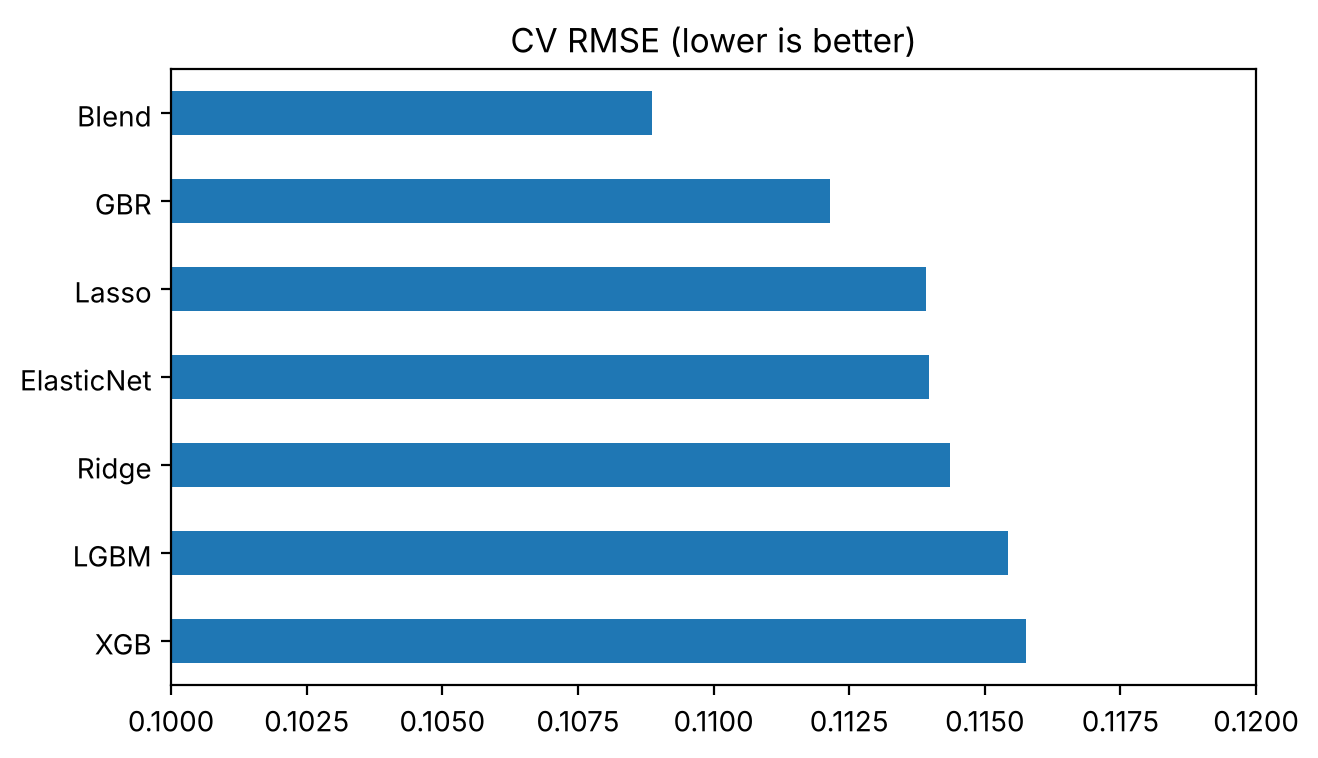

In [4]:
w, _ = nnls(oof.values, y.values); w = w / w.sum()
weights = pd.Series(w, index=oof.columns); print(weights.round(3).to_string())
print(f'\nBlend CV RMSE = {rmse(oof.values @ w):.4f}')

scores = pd.Series({k: rmse(oof[k]) for k in oof}); scores['Blend'] = rmse(oof.values @ w)
scores.sort_values(ascending=False).plot.barh(figsize=(7,4), title='CV RMSE (lower is better)'); plt.xlim(0.10, 0.12); plt.show()

## 4.4 Diagnostics
Residuals should be centred on zero with no pattern. Big misses are worth a look.

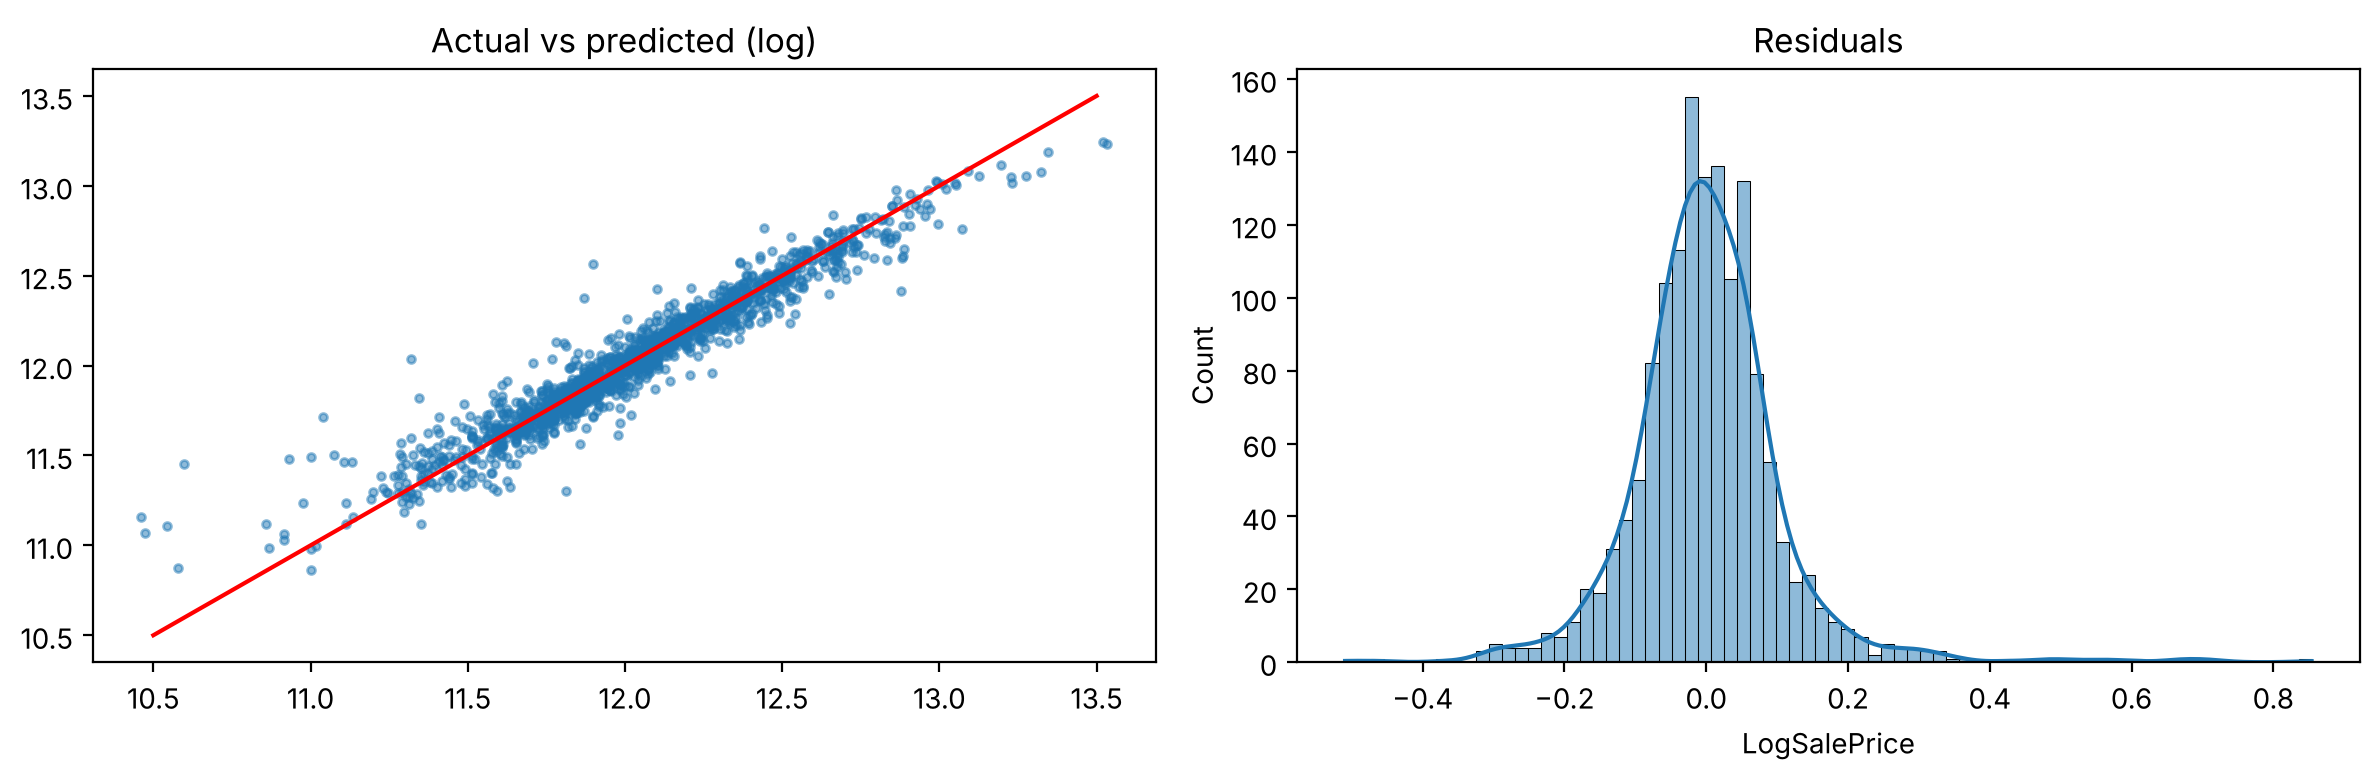

In [5]:
pred = oof.values @ w
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].scatter(y, pred, s=8, alpha=.5); ax[0].plot([10.5,13.5],[10.5,13.5],'r'); ax[0].set_title('Actual vs predicted (log)')
sns.histplot(pred - y, kde=True, ax=ax[1]); ax[1].set_title('Residuals'); plt.tight_layout(); plt.show()

## 4.5 Feature importance (GBR)

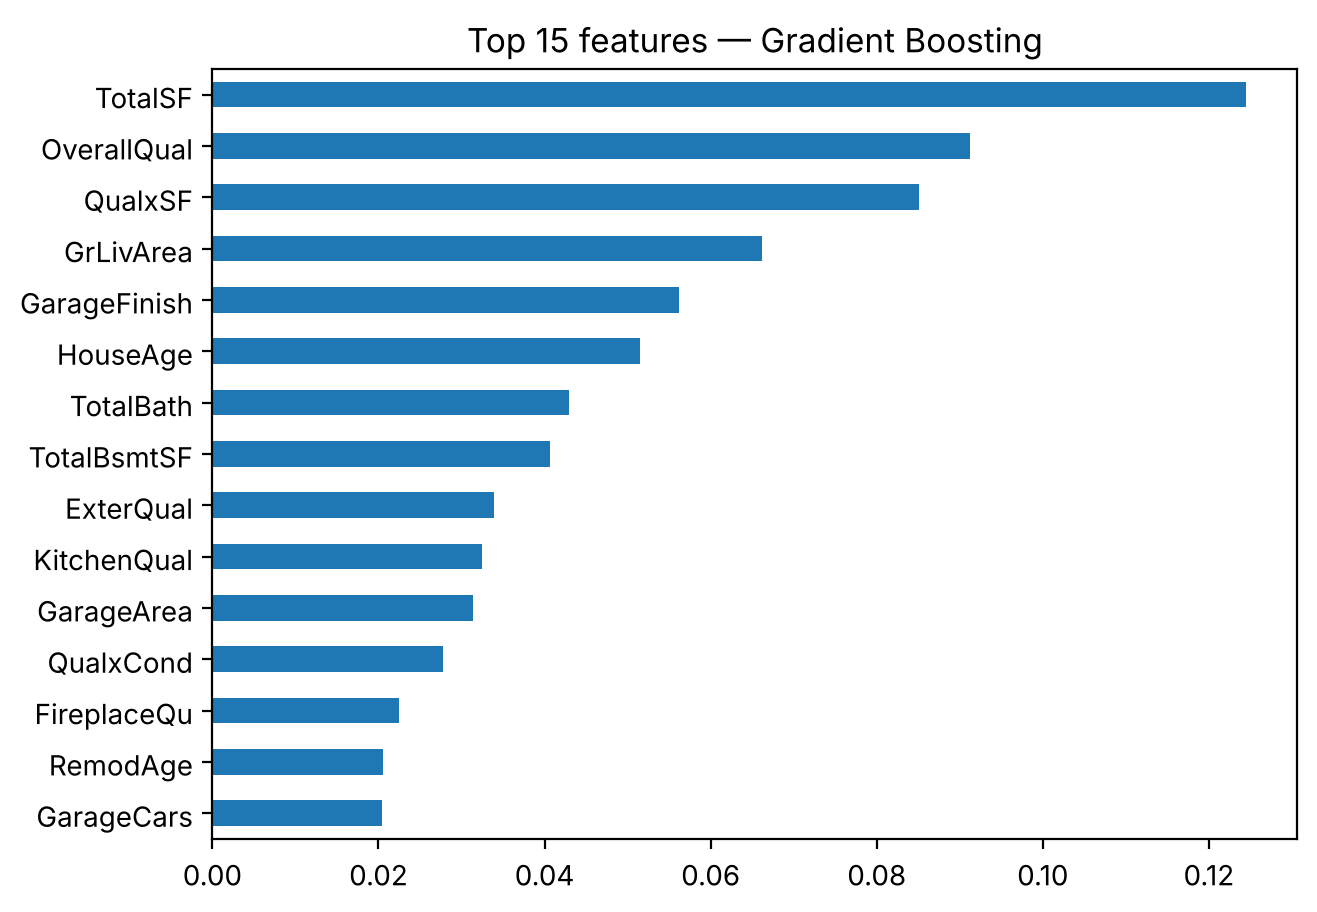

In [6]:
gbr = models['GBR'].fit(X, y)
pd.Series(gbr.feature_importances_, index=X.columns).nlargest(15).sort_values().plot.barh(figsize=(7,5), title='Top 15 features — Gradient Boosting'); plt.show()

## 4.6 Fit on full data & write submission

In [7]:
preds = pd.DataFrame({name: m.fit(X, y).predict(X_test) for name, m in models.items()})[oof.columns]
final = np.expm1(preds.values @ w)          # back from log scale to dollars
sub = pd.DataFrame({'Id': ids, 'SalePrice': final})
sub.to_csv('../submission.csv', index=False)
print(sub.shape, sub.SalePrice.describe().round(0).to_dict())
sub.head()

(1459, 2) {'count': 1459.0, 'mean': 178592.0, 'std': 77524.0, 'min': 53297.0, '25%': 127619.0, '50%': 157735.0, '75%': 210725.0, 'max': 786857.0}


,Id,SalePrice
0,1461,119876.418870
1,1462,158966.536448
2,1463,185924.714246
3,1464,198722.073415
4,1465,191281.122230
